# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

> **Примітка.** У Google Colab не вдалося встановити Ollama: завантаження з ollama.com і з GitHub повертало помилку 504 (мережевий збій на стороні сеансу Colab). Тому клітинки 0.1, 0.2 і 1.0 нижче завершуються помилкою або пропущені. У розділі 1 ті самі моделі Qwen3-1.7B (Base та Instruct) запущено через бібліотеку transformers у форматі fp16, а не Q4_K_M через Ollama. Для цього перед розділом 1.2 додано клітинку, що визначає функції generate_raw, chat і compare_thinking з тим самим інтерфейсом. Через це числа токенів і часу можуть відрізнятися від тих, що були б в Ollama. Ollama використано локально в частині 1 лабораторної

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
curl: (22) The requested URL returned error: 504


FileNotFoundError: [Errno 2] No such file or directory: 'ollama'

### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

Ollama у Colab не вдалося встановити (помилка 504 при завантаженні), тому в розділі 1 ті самі моделі Qwen3-1.7B (Base та Instruct) запущено через transformers. Функції generate_raw, chat і compare_thinking мають той самий інтерфейс. Для частини 1 завдання Ollama використано локально.

In [ ]:
import gc, time, torch
from transformers import AutoModelForCausalLM, AutoTokenizer

BASE_MODEL = "Qwen/Qwen3-1.7B-Base"
INSTRUCT_MODEL = "Qwen/Qwen3-1.7B"
_cache = {}

def load(name):
    """Завантажує модель і токенізатор у GPU один раз."""
    if name not in _cache:
        tok = AutoTokenizer.from_pretrained(name)
        mdl = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16, device_map="cuda")
        _cache[name] = (tok, mdl)
    return _cache[name]

def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template, як це бачить Base-модель."""
    tok, mdl = load(model)
    inputs = tok(prompt, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = mdl.generate(**inputs, max_new_tokens=max_tokens, do_sample=False)
    return tok.decode(out[0, inputs.input_ids.shape[1]:], skip_special_tokens=True)

def chat(model, prompt, think=False, max_tokens=3000):
    """Запит у форматі діалогу; повертає словник у такому ж форматі, як раніше давала Ollama."""
    tok, mdl = load(model)
    text = tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=think)
    inputs = tok(text, return_tensors="pt").to("cuda")
    torch.cuda.synchronize(); start = time.perf_counter()
    with torch.no_grad():
        out = mdl.generate(**inputs, max_new_tokens=max_tokens, do_sample=False)
    torch.cuda.synchronize(); dur = time.perf_counter() - start
    new = out[0, inputs.input_ids.shape[1]:]
    raw = tok.decode(new, skip_special_tokens=True)
    thinking, content = "", raw
    if "</think>" in raw:
        thinking, content = raw.split("</think>", 1)
        thinking = thinking.replace("<think>", "").strip()
    return {"message": {"content": content.strip(), "thinking": thinking},
            "eval_count": len(new), "eval_duration": dur * 1e9}

def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

print("Готово: функції generate_raw, chat, compare_thinking визначено")

Готово: функції generate_raw, chat, compare_thinking визначено


### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка впадає в Море? Як називається найбільша річка Франції, яка впадає в Атлантичне море? Як називається найбільша річка Франції, яка впадає в Б


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Столиця Франції — це місто **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 184 | генерація: 8.8 с
--- відповідь:
Розглянемо крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди 2 пакети по 4 яблука.**  
   - Кожен пакеті 4 яблука, тому 2 пакети — це $2 \times 4 = 8$ яблук.  
   - У кошику стало $3 + 8 = 11$ яблук.  
3. **Марія зʼїла 2 яблука.**  
   - У кошику залишилося $11 - 2 = 9$ яблук.

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 926 | генерація: 41.8 с
--- міркування (2410 символів), початок:
Okay, let's see. So the problem is about a cat's bowl. Initially, there are 3 apples in the bowl. Then Maria puts in two packages, each with 4 apples. After that, she eats 2 apples. The question is, how many apples are left in the bowl?

Alright, let me break this down step by step. First, the starting point is 3 apples. Then Maria adds two packages. Each package has 4 apples. So, if there are two packages, each with 4 apples, that's 2 times 4. Let me calculate that: 2 * 4 is 8. So, adding that to the origi

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 193 | генерація: 8.7 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, розглянемо кожну літеру:

**Трансформер** — це слово з наступними літерами:

1. **Т**  
2. **р**  
3. **а**  
4. **н**  
5. **с**  
6. **ф**  
7. **о**  
8. **р**  
9. **м**  
10. **е**  
11. **р**  
12. **ь**  

Таким чином, літера **«р»** зустрічається **3 рази**.

**Відповідь: 3**

=== think=True | токенів: 771 | генерація: 35.9 с
--- міркування (1763 символів), початок:
Okay, let's see. The user is asking how many times the letter 'r' appears in the word "трансформер". First, I need to make sure I understand the word correctly. The word is "трансформер" in Ukrainian, right? Let me break it down.

So, the word is "трансформер". Let me write it out: т, р, а, н, с, т, о, м, е, р. Wait, is that right? Let me check again. The word is "трансформер". Breaking it down letter by letter:

1. т (t)
2. р (r)
3. а (a)
4. н (n)
5. с (s)
6. т (t)
7. о

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

**Відповідь на запитання «Чому так».** У моєму запуску без міркувань модель дала відповідь 3, але через вигадане написання слова (12 літер з «ь» замість 11), тобто правильно випадково. З міркуваннями вона записала слово як «т, р, а, н, с, т, о, м, е, р» і відповіла 2. Пояснення і код наведено в питанні 1 розділу 3.

**Де міркування допомагають, а де витрачають токени.** Див. питання 9: на задачі про верстати вони змінили відповідь зі «100» на правильну «5» (2577 токенів проти 8), а на множеннях і простих питаннях відповідь та сама, лише в десятки разів більше токенів.

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
_cache.clear()
gc.collect()
torch.cuda.empty_cache()
print(f"Зайнято GPU: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Зайнято GPU: 0.01 GB


In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.05,8.64,17.47,2.67,2.40,55.22,23.71
int8,4.42,5.01,6.35,2.67,2.40,58.25,26.17
int4,2.73,3.32,3.08,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.14,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

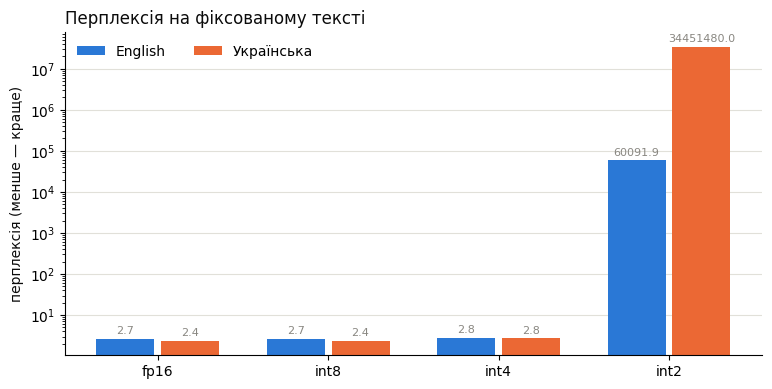

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


In [ ]:
summary.to_csv("summary_4b.csv")

### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "B", 2: "=", 3: "A", 4: "B", 5: "="}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,int4
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,однаково
2,Explain in three sentences why the sky is blue.,fp16,int4,fp16
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,однаково


fp16 краща: 2, int4 краща: 1, однаково: 2


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

## 3. Відповіді на теоретичні питання (0.1)


Питання 1. Літера «р» у слові «трансформер»

In [ ]:
word = "трансформер"
tok, _ = load(INSTRUCT_MODEL)
print("Справжня кількість «р»:", word.count("р"))
for w in (word, " " + word):
    ids = tok(w, add_special_tokens=False).input_ids
    print(repr(w), "→", len(ids), "токенів:", [tok.decode([i]) for i in ids])

print(chat(INSTRUCT_MODEL, "Скільки разів літера «р» трапляється в цьому ряду: т, р, а, н, с, ф, о, р, м, е, р? Порахуй уважно.")["message"]["content"])

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Справжня кількість «р»: 3
'трансформер' → 5 токенів: ['т', 'ран', 'с', 'форм', 'ер']
' трансформер' → 5 токенів: [' т', 'ран', 'с', 'форм', 'ер']
Візьмемо рядок:

**т, р, а, н, с, ф, о, р, м, е, р**

Тепер підрахуємо кількість літер **«р»**.

Розглянемо кожну літеру:

1. **т** — ні  
2. **р** — **1**  
3. **а** — ні  
4. **н** — ні  
5. **с** — ні  
6. **ф** — ні  
7. **о** — ні  
8. **р** — **2**  
9. **м** — ні  
10. **е** — ні  
11. **р** — **3**

**Відповідь: 3 рази.**


Модель працює не з літерами, а з токенами, тобто шматками слів. Код показав, що «трансформер» розбивається на п'ять токенів: «т», «ран», «с», «форм», «ер». Три літери «р» ховаються всередині токенів «ран», «форм» і «ер», і модель не бачить їх окремо. Щоб порахувати літери, їй треба спершу відновити написання слова з токенів, і саме тут вона помиляється. У моєму запуску без міркувань модель розписала слово з вигаданою літерою «ь» наприкінці (12 літер замість 11) і відповіла «3». Це правильно лише випадково, бо вигадана літера не була «р». З міркуваннями вона записала «т, р, а, н, с, т, о, м, е, р», тобто замінила «ф» на «т» і загубила другу «р», тож відповіла «двічі». Міркування не допомагають, бо починаються з цього ж хибного розкладу і самі складаються з токенів. Коли літери розділені комами, кожна стає окремим токеном, і модель порахувала правильно (3). У тексті ноутбука сказано, що модель помиляється в обох режимах. У мене так вийшло лише з міркуваннями, бо тут запущено Qwen3-1.7B у fp16 через transformers, а не Q4-версію з Ollama.

Питання 2. fp16 → int2

Від fp16 до int8 перплексія не змінилася (2,67 для англійської й 2,40 для української). В int4 вона трохи зросла (2,81 і 2,76), а в int2 вибухнула до 60 092 і 34 451 480. chrF становить 55,22 (fp16), 58,25 (int8), 55,34 (int4) і 0,19 (int2). BLEU: 23,71, 26,17, 29,79 і 0,12. Найбільший стрибок, на кілька порядків, між int4 і int2. На вагу залишається лише 4 можливі значення, і модель перестає працювати. Те, що в int8 та int4 chrF і BLEU навіть вищі, ніж у fp16, пояснюється малою вибіркою: перекладів лише 10, і кілька вдалих чи невдалих фраз зсувають бал. Це не означає, що квантизована модель краща.

Питання 3. Англійська проти української

In [ ]:
cols = ["перплексія, English", "перплексія, Українська"]
display((summary[cols] / summary.loc["fp16", cols]).round(2))

,"перплексія, English","перплексія, Українська"
fp16,1.00,1.00
int8,1.00,1.00
int4,1.05,1.15
int2,22506.31,14354783.33


Зростання нерівномірне. В int4 перплексія англійської виросла в 1,05 раза, а української в 1,15 раза, тобто українська втрачає втричі більше. В int2 різниця ще більша: англійська зросла приблизно в 22 500 разів, українська приблизно в 14,4 млн. Це відповідає висновку слайда про те, що квантизація сильніше б'є по мовах, менш представлених у навчальних даних, до яких належить і українська. Абсолютні значення перплексії між мовами порівнювати не можна (див. питання 13), а відносне зростання можна.

Питання 4. Сліпе порівняння та метрики

У сліпому порівнянні fp16 виявилась кращою у двох запитах із п'яти (про небо й про план підготовки), int4 в одному (лист викладачеві), в двох я не побачила різниці (пояснення квантизації та код паліндрома). Метрики показують, що int4 майже не відрізняється від fp16: перплексія 2,81 проти 2,67, chrF 55,34 проти 55,22, а BLEU навіть вищий (29,79 проти 23,71). Очима різницю я помітила там, де метрики майже не змінилися. Відповідь int4 про небо коротша й без фізичної деталі про залежність розсіювання від довжини хвилі. План підготовки в int4 починається незграбною фразою «з акцентом на засвоєння основних інших навичок» і менш структурований. У перекладах chrF для int4 такий самий, як для fp16, хоча в реченні про бібліотеку з'явилась вигадка «відкрита тільки з 1 по 7». Навпаки, у листі викладачеві int4 мені сподобалась більше, бо була короткою й по суті, а fp16 мала зайві вступні фрази. Метрики на малій вибірці не вловлюють змістових помилок, а очі їх помічають, хоча теж не однозначно.

Питання 5. Правильний переклад, що відрізняється від еталона

In [ ]:
i = 4
ref = TRANSLATION[i][1]
print("Еталон:", ref, "\n")
for name, r in records.items():
    pred = r["переклади"][i]
    c = chrf.compute(predictions=[pred], references=[[ref]])["score"]
    b = bleu.compute(predictions=[pred], references=[[ref]])["score"]
    print(f"{name:5} chrF={c:5.1f}  BLEU={b:5.1f}  | {pred}")

Еталон: Завтра буде дощ, тож візьміть парасольку. 

fp16  chrF= 37.1  BLEU= 13.1  | Завтра піде дощ, тому взміть засіб.
int8  chrF= 57.0  BLEU= 12.5  | Завтра піде дощ, тому взміть з собою парасольку.
int4  chrF= 50.4  BLEU= 36.6  | Завтра буде дощ, тому взміть засіб.
int2  chrF=  0.3  BLEU=  0.6  | }again \蚊} taken 
everh.  
  
again  
  
}  
\" \  
afi \} Intercept Taken �IRMWARE\x "}ight � Taken � hatch Taken\"  
  
 licked  
 
 Taken   Taken haled 
ightight eat  
ight Taken  %{  � Filight �wt °tight"\
"\
  
` \h oats  face \ taken whe by \


Це речення «It is going to rain tomorrow, so take an umbrella.» з еталоном «Завтра буде дощ, тож візьміть парасольку.». Переклад int8 «Завтра піде дощ, тому візьміть з собою парасольку.» правильний за змістом, але інший за словами. Він має chrF 57,0 (найвищий серед усіх варіантів) і BLEU 12,5 (найнижчий серед трьох робочих). BLEU рахує збіги слів і послідовностей слів: «піде» замість «буде», «тому» замість «тож» і додане «з собою» ламають біграми, тож бал малий. chrF рахує збіги символів, і через спільні основи й закінчення («Завтра», «дощ», «візьміть», «парасольку») реагує значно м'якше. Показово, що int4 перекладає неправильно («візьміть засіб» замість «парасольку»), але має BLEU 36,6, утричі вищий, бо збігся початок «Завтра буде дощ,». Обидві метрики не розуміють змісту. Вони карають правильну перефразовану відповідь і можуть пробачити помилкову.

Питання 6. Пам'ять і швидкість

In [ ]:
from transformers import AutoConfig
mem = summary["памʼять моделі, GB"]
print("У скільки разів менша памʼять, ніж у fp16:")
display((mem.loc["fp16"] / mem).round(2))
print("Швидкість, tokens/s:")
display(summary["tokens/s"])
cfg = AutoConfig.from_pretrained(MODEL_ID)
print(f"Ембединги в fp16: {cfg.vocab_size * cfg.hidden_size * 2 / 1e9:.2f} GB")

У скільки разів менша памʼять, ніж у fp16:


,"памʼять моделі, GB"
fp16,1.00
int8,1.82
int4,2.95
int2,4.45


Швидкість, tokens/s:


,tokens/s
fp16,17.47
int8,6.35
int4,3.08
int2,3.14


Ембединги в fp16: 0.78 GB


Пам'ять зменшилась з 8,05 GB до 4,42 GB для int8 (у 1,82 раза), до 2,73 GB для int4 (у 2,95 раза) і до 1,81 GB для int2 (у 4,45 раза). Це менше за теоретичні 2, 4 і 8 разів, бо квантизуються лише ваги лінійних шарів (близько 3,63 млрд параметрів). Ембединги (0,39 млрд параметрів, 0,78 GB) і нормалізації лишаються у fp16, і ще додаються масштаби для блоків ваг. Для int2 це дає 3,63 × 0,25 ≈ 0,91 GB плюс 0,78 GB незмінної частини і трохи масштабів, тобто приблизно 1,8 GB, що збігається з таблицею. Генерація не прискорилась, а сповільнилась: 17,47 tokens/s у fp16, 6,35 в int8, 3,08 в int4 і 3,14 в int2. На T4 ваги перед кожним множенням розпаковуються назад у 16 біт (для int4 й int2 на чистому PyTorch), і ці витрати перекривають виграш від меншого читання з пам'яті. Тут квантизація економить пам'ять, але не прискорює.

Питання 7. Base-модель і промпт, щоб вона відповіла

In [ ]:
prompt = ("Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n"
          "Питання: Яка столиця Італії?\nВідповідь: Рим\n\n"
          "Питання: Яка столиця Франції?\nВідповідь:")
out = generate_raw(BASE_MODEL, prompt, max_tokens=10)
print(repr(out))
print("Відповідь:", out.strip().split("\n")[0])

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

' Париж\n\nПитання: Я'
Відповідь: Париж


Base-модель пройшла лише попереднє тренування на передбачення наступного токена в інтернет-текстах і не вчилась відповідати на запити. Фраза «Яка столиця Франції?» без контексту схожа на початок списку питань вікторини, тому модель продовжує список: у моєму запуску вона писала «Як називається найбільша річка Франції? …» і так далі. Щоб вона відповіла, я дала їй шаблон «Питання → Відповідь» з двома прикладами (Німеччина і Італія) і залишила третє питання без відповіді. Модель повернула ' Париж\n\nПитання: Я', і після обрізання за першим рядком маємо «Відповідь: Париж». Залишок «Питання: Я» показує, що Base-модель сама не зупиняється й продовжує шаблон, тому застосовуємо ліміт max_tokens=10 та split("\n")[0].

Питання 8. Міркування: токени, час, мова

Без міркувань модель згенерувала 184 токени за 8,8 с, з міркуваннями 926 токенів за 41,8 с. Це в 5 разів більше токенів і в 4,8 раза довше, при цьому швидкість генерації майже однакова (близько 21 і 22 tokens/s), тобто час росте пропорційно кількості токенів. Різниця не гігантська, бо й без режиму міркувань модель сама розписала розв'язок по кроках. Обидва режими дали правильну відповідь 9. Міркує вона англійською, бо англійська (поряд з китайською) домінує в навчальних даних і в навчанні міркуванню, тож «внутрішній монолог» найкраще працює нею. У моєму запуску видно й ціну цього: міркування починаються зі слів «the problem is about a cat’s bowl», тобто слово «кошик» модель спершу сприйняла хибно, і потім сама виправилась.

Питання 9. Задача, де міркування допомагає

In [ ]:
import re

def last_number(text):
    text = re.sub(r"(?<=\d)[ \u00a0](?=\d)", "", text)
    nums = re.findall(r"\d+", text)
    return nums[-1] if nums else None

TASKS = [
    ("Скільки буде 38 × 47? Відповідай лише числом.", "1786"),
    ("Скільки буде 123 × 456? Відповідай лише числом.", "56088"),
    ("У Ані втричі більше цукерок, ніж у Каті. Разом у них 48. Скільки цукерок у Каті? Відповідай лише числом.", "12"),
    ("5 верстатів роблять 5 деталей за 5 хвилин. За скільки хвилин 100 верстатів зроблять 100 деталей? Відповідай лише числом.", "5"),
    ("Яке число наступне: 2, 6, 12, 20, 30, ...? Відповідай лише числом.", "42"),
    ("Скільки днів між 3 березня і 17 квітня в невисокосному році? Відповідай лише числом.", "45"),
]
rows = []
for prompt, expected in TASKS:
    row = {"задача": prompt[:40] + "…", "очікується": expected}
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        row[f"think={think}"] = last_number(r["message"]["content"])
        row[f"токенів, think={think}"] = r["eval_count"]
    rows.append(row)
display(pd.DataFrame(rows))

,задача,очікується,think=False,"токенів, think=False",think=True,"токенів, think=True"
0,Скільки буде 38 × 47? Відповідай лише чи…,1786,1786,13,1786,859
1,Скільки буде 123 × 456? Відповідай лише …,56088,56088,32,56088,1785
2,"У Ані втричі більше цукерок, ніж у Каті.…",12,12,124,12,317
3,5 верстатів роблять 5 деталей за 5 хвили…,5,100,8,5,2577
4,"Яке число наступне: 2, 6, 12, 20, 30, ..…",42,42,116,42,274
5,Скільки днів між 3 березня і 17 квітня в…,45,14,39,44,3000


Я перевірила шість задач з інструкцією «Відповідай лише числом.». Єдина, де міркування змінило результат на правильний, це: «5 верстатів роблять 5 деталей за 5 хвилин. За скільки хвилин 100 верстатів зроблять 100 деталей? Відповідай лише числом.». Без міркувань модель відповіла «100» (8 токенів), що є хибною відповіддю за візерунком «5 → 100». З міркуваннями вона відповіла «5» (2577 токенів), що є правильно: кожен верстат робить одну деталь за 5 хвилин, тож сто верстатів зроблять сто деталей за ті самі 5 хвилин. Міркування допомагають там, де потрібно записати проміжні кроки, а миттєва відповідь спирається на хибну схожість із шаблоном. Де міркування лише витрачають токени: на множеннях 38 × 47 і 123 × 456 обидва режими дали правильну відповідь, але з міркуваннями 859 і 1785 токенів замість 13 і 32. На задачі про цукерки було 124 проти 317 токенів, на числовому ряді 116 проти 274, відповідь однакова. Задача про кількість днів між 3 березня і 17 квітня показала, що міркування не гарантують успіху: без них відповідь 14, з ними 44 після вичерпання ліміту в 3000 токенів, а правильно 45.

Питання 10. temperature: 0 і seed: 1

temperature: 0 робить декодування жадібним: модель завжди бере найімовірніший токен, і випадковості немає. seed: 1 додатково фіксує генератор випадкових чисел, тож відповіді відтворюються при кожному запуску. Це потрібно, щоб порівнювати режими й моделі чесно: різниця у відповідях має бути наслідком моделі чи налаштувань, а не випадкового семплінгу. У моєму Colab-варіанті (Ollama не вдалося встановити, тому використано transformers) цю роль виконує do_sample=False.

Питання 11. fp16 проти bf16 і T4

In [ ]:
print(torch.cuda.get_device_capability())

(7, 5)


torch.cuda.get_device_capability() на T4 повертає (7, 5), тобто архітектуру Turing. Апаратна підтримка bf16 починається з архітектури Ampere (compute capability 8.0 і вище, наприклад A100), тож на T4 її немає. Тому в секції 2 використано fp16, а різниця між форматами для запуску готової моделі практично непомітна. З цим пов'язана й перевірка get_device_capability()[0] < 8 у коді, де для T4 підставляється розпаковка ваг на чистому PyTorch.

Питання 12 і 13. Параметри, пам'ять, перплексія на випадкових словах

In [ ]:
import random
_cache.clear(); globals().pop("model", None)
gc.collect(); torch.cuda.empty_cache()

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)

# Питання 12
n = sum(p.numel() for p in model.parameters())
emb = model.get_input_embeddings().weight.numel()
print(f"параметрів: {n/1e9:.2f} млрд, з них ембединги: {emb/1e9:.2f} млрд")
print(f"fp16 за формулою (параметри × 2 байти): {n*2/1e9:.2f} GB")
print(f"памʼять моделі в таблиці 2.4: {summary.loc['fp16','памʼять моделі, GB']:.2f} GB")

# Питання 13
random.seed(0)
for lang, text in PPL_TEXT.items():
    words = text.replace(".", "").replace(",", "").replace(":", "").replace("—", "").split()
    shuffled = " ".join(random.sample(words, len(words)))
    print(f"{lang}: осмислений текст = {perplexity(model, text):.1f}, перемішані слова = {perplexity(model, shuffled):.1f}")

del model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

параметрів: 4.02 млрд, з них ембединги: 0.39 млрд
fp16 за формулою (параметри × 2 байти): 8.04 GB
памʼять моделі в таблиці 2.4: 8.05 GB
English: осмислений текст = 2.7, перемішані слова = 415.2
Українська: осмислений текст = 2.4, перемішані слова = 14.4


Модель Qwen3-4B-Instruct-2507 має 4,02 млрд параметрів, з яких 0,39 млрд це ембединги. За формулою з лекції (параметри × байти на вагу) у fp16 це 4,02 × 10⁹ × 2 байти = 8,04 GB. У таблиці 2.4 «пам'ять моделі» для fp16 дорівнює 8,05 GB. Збіг майже повний, різниця 0,01 GB припадає на службові буфери.

Перплексія це експонента від середньої похибки передбачення наступного токена. Грубо кажучи, це кількість варіантів, з яких модель у середньому «вагається»: що менша, то краще модель передбачає текст. Порівнювати її між мовами не можна, бо вона рахується на токен, а мови токенізуються по-різному. Українське слово розбивається на більше токенів, і багато з них (закінчення) легко передбачити, що знижує середнє. Тому в таблиці для української 2,40, нижче за англійську 2,67, хоча модель в українській слабша. На перемішаних словах перплексія для англійської зросла з 2,7 до 415,2, а для української з 2,4 до 14,4. Слова ті самі, але без зв'язку між ними наступне слово не передбачуване, і модель «дивується» щоразу. Менше зростання в українській, імовірно, пояснюється тим, що значну частку токенів становлять передбачувані продовження слів, які розбавляють середнє. Це ще один доказ того, що між мовами перплексія не порівнюється.

Питання 14. Пік VRAM і памʼять моделі

Різниця між піком і пам'яттю моделі майже стала для всіх варіантів: 8,64 − 8,05 = 0,59 GB для fp16, 0,59 для int8 і int4, 0,58 для int2. Вона не залежить від розрядності ваг. Це пам'ять на KV-кеш (ключі й значення уваги для вже оброблених токенів), активації, тимчасові буфери й логіти розміром «довжина × словник» (близько 152 тис. токенів), які особливо великі під час підрахунку перплексії. При коротких промптах KV-кеш малий (для цієї моделі близько 0,15 MB на токен), але він росте лінійно з довжиною контексту і при довгому контексті може перевищити розмір самих ваг.

Питання 15. Скільки разів обрано кожен варіант і наскільки це надійно

У сліпому порівнянні я обрала fp16 у двох запитах, int4 в одному, «однаково» у двох. П'ять порівнянь це дуже мало для висновків. Навіть при 5:0 на користь одного варіанта двосторонній біноміальний тест дав би p = 0,0625, тобто нижче порога 0,05 це б не потрапило. Серед трьох «рішучих» голосів у мене 2:1, і це статистично не відрізняється від підкидання монети. Щоб надійно виявити помірну перевагу (60 % проти 40 %), потрібно приблизно 200 порівнянь, а для 55 % проти 45 % близько 800. Також потрібні різні запити, кілька незалежних оцінювачів і випадковий порядок A/B, що тут уже забезпечено.

Питання 16. Як «ламається» int2

За виводом 2.6, int2 повністю втрачає зв'язну мову: у відповідях випадкові токени, не пов'язані із запитом. Типові ознаки: суміш мов («bet», «had», «again» поруч із китайськими «八», «航», «前所»), службові символи («°», «**», лапки й дефіси), зациклення на одному токені («\ \ \ \ …» аж до ліміту довжини), ігнорування мови й формату запиту. Код у запиті 5 перетворився на набір лапок і дефісів. Перекладом стали слова «taken», «ever», «between». Це узгоджується з перплексією: англійська 6·10⁴ того ж порядку, що й вгадування навмання серед ~152 тис. токенів, а українська 3,4·10⁷ на кілька порядків гірша, тобто модель упевнено помиляється. В int4 такого розвалу немає, але дрібні ознаки помітні: незграбні звороти («з меншою відповідністю до об'ємних ресурсів», «основних інших навичок»), граматична помилка («ваги можуть бути зображено») і вигадане «Бібліотека відкрита тільки з 1 по 7». Схожі вади є й у fp16 та int8 («обмеженою відповідністю», «засіб» замість «парасольку»), тож частина з них це слабкість самої моделі в українській, а не наслідок квантизації.

Питання 17. Менша модель (Qwen3-1.7B)

In [ ]:
records_4b, summary_4b = records, summary

MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

def generate(model, prompt, max_new_tokens):
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                         add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start

records = {}
for name, config in VARIANTS.items():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)
    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")
    del model

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

fp16: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int8: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [ ]:
summary_17b = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"], "пік VRAM, GB": r["пік VRAM, GB"], "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    } for name, r in records.items()
}).T.round(2)
records_17b = records
cols = ["перплексія, English", "перплексія, Українська"]
display(summary_17b)
print("Відносне зростання перплексії (1.7B):"); display((summary_17b[cols] / summary_17b.loc["fp16", cols]).round(2))
print("Відносне зростання перплексії (4B):");   display((summary_4b[cols] / summary_4b.loc["fp16", cols]).round(2))
display(summary_17b[["chrF перекладу", "BLEU перекладу"]]); display(summary_4b[["chrF перекладу", "BLEU перекладу"]])

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,6.89,7.82,22.62,4.35,3.10,48.74,23.83
int8,5.48,6.42,14.23,4.45,3.11,47.44,22.54
int4,4.82,5.76,7.19,7.52,5.60,29.01,4.30
int2,4.47,5.40,7.49,438691.38,5951889.50,0.24,0.26


Відносне зростання перплексії (1.7B):


,"перплексія, English","перплексія, Українська"
fp16,1.00,1.00
int8,1.02,1.00
int4,1.73,1.81
int2,100848.59,1919964.35


Відносне зростання перплексії (4B):


,"перплексія, English","перплексія, Українська"
fp16,1.00,1.00
int8,1.00,1.00
int4,1.05,1.15
int2,22506.31,14354783.33


,chrF перекладу,BLEU перекладу
fp16,48.74,23.83
int8,47.44,22.54
int4,29.01,4.30
int2,0.24,0.26


,chrF перекладу,BLEU перекладу
fp16,55.22,23.71
int8,58.25,26.17
int4,55.34,29.79
int2,0.19,0.12


Квантизація б'є по меншій моделі набагато сильніше. В int4 перплексія 1.7B зросла відносно fp16 у 1,73 раза для англійської (з 4,35 до 7,52) і в 1,81 раза для української (з 3,10 до 5,60), тоді як у 4B лише у 1,05 і 1,15 раза. chrF у 1.7B упав із 48,74 до 29,01, а BLEU з 23,83 до 4,30. У 4B у int4 chrF не просів (55,22 → 55,34). В int8 обидві моделі майже без втрат (1,02 і 1,00 для 1.7B), а в int2 обидві ламаються (перплексія 4·10⁵ і 6·10⁶ у 1.7B, chrF 0,24). Причина в тому, що в меншій моделі менше запасу надлишковості: кожна вага несе більше інформації, і її грубе округлення шкодить сильніше. Порівнювати варто відносні зміни, а не абсолютні значення, бо моделі різні. Для 1.7B у generate довелось вимкнути міркування (enable_thinking=False), інакше відповіді починались би з <think> і псували б переклади. Колонки «пам'ять моделі» та «пік VRAM» для 1.7B у таблиці завищені приблизно на 3 GB (fp16-модель з 2 млрд параметрів не може займати 6,89 GB). Імовірно, у пам'яті GPU лишилась модель із попередніх клітинок, тож ці дві колонки не інтерпретую. Перплексія, chrF і BLEU цим не зачеплені.

Питання 18. OLLAMA_NUM_PARALLEL

Параметр визначає, скільки запитів Ollama обслуговує одночасно однією завантаженою моделлю. Генерація обмежена пропускною здатністю пам'яті: щоб видати токен, треба прочитати всі ваги. Коли кілька запитів обробляються одним батчем, ваги читаються один раз на всіх, тож сумарна пропускна здатність (throughput) зростає, а швидкість для окремого користувача падає лише трохи. Платимо пам'яттю: для кожного паралельного слота потрібен власний KV-кеш, тому виділений контекст дорівнює num_ctx × NUM_PARALLEL. Запити понад ліміт стають у чергу, і TTFT зростає. Це видно в bench.py при різній кількості клієнтів.

Питання 19. Чому моделі зберігаються в bf16

bf16 займає 16 біт, як і fp16, але має 8 біт на порядок (як fp32) замість 5, тобто такий самий діапазон значень, як fp32, і менше біт на мантису. Завдяки цьому під час навчання не виникає переповнень і зануляння градієнтів, і не потрібне додаткове масштабування втрат, яке вимагає fp16. Нижча точність мантиси для нейромереж не критична, а пам'ять удвічі менша за fp32. Тому моделі навчають у bf16 і зберігають у ньому, а fp16 та квантизовані формати отримують із нього.

Слайди лекції додають, що причина не лише в навчанні. Під час інференсу в LLM виникають викиди активацій, окремі значення сягають сотень і тисяч, а суми квадратів у LayerNorm і скалярні добутки в attention ростуть ще швидше. Максимум fp16 це ±65 504, тож такі значення переповнюються в inf. Ваги й обчислення мають бути в одному форматі: модель, натренована в bf16, її активації «звикли» до діапазону bf16, у fp16 може давати NaN. Низьку точність bf16 (крок біля 1 близько 0,0078) нейромережі переносять добре, бо похибка в третьому знаку це шум, до якого модель пристосувалась під час тренування.

Питання 20. Навіщо протокол OpenAI

API /v1/chat/completions став де-факто стандартом: майже всі клієнтські бібліотеки, фреймворки й застосунки вміють з ним працювати. Рантайми (Ollama, llama.cpp, LM Studio, vLLM) імітують його, тому для переходу від хмарної моделі до локальної достатньо змінити base_url, як у bench.py і stream_demo.py. Зв'язок із ChatGPT прямий: цей формат OpenAI створила для моделей, що стоять за ChatGPT (повідомлення з ролями system, user, assistant, стрімінг). Після успіху ChatGPT екосистема побудувалась навколо нього, і сумісність із ним стала умовою, щоб нові моделі й сервери можна було підключити до наявних інструментів.

## 4. Звіт до лабораторної (1.8)


**Залізо:**
| Параметр | Значення | Звідки взято |
|---|---|---|
| Ноутбук | ASUS VivoBook X712EA | PowerShell, Win32_ComputerSystem |
| Процесор | Intel Pentium Gold 7505 @ 2.00 GHz | PowerShell, (Get-CimInstance Win32_Processor).Name |
| RAM | 8 ГБ DDR4-3200, одна планка Micron | PowerShell, Win32_PhysicalMemory |
| Відеокарта | Intel UHD Graphics (вбудована) | PowerShell, Win32_VideoController |
| VRAM | окремої немає, використовується RAM | Диспетчер завдань, вкладка ГП |
| Пропускна здатність пам'яті | 25,6 GB/s (3200 МТ/с × 8 байт × 1 канал) | розрахунок за даними PowerShell |
| Доступно для моделі | 3,8 ГБ | Диспетчер завдань, «Доступно», після закриття зайвих програм |

**Розрахунок:**

Формули зі слайдів лекції 5: пам'ять ≈ P × Q/8 × (1+O), де O = 10-30 %; KV на токен = 2 × шари × KV-голови × розмір голови × байти (для Qwen3-1.7B: 2 × 28 × 8 × 128 × 2 = 112 KiB на токен, для контексту 4096 це ≈ 0,47 GB); швидкість ≲ пропускна здатність пам'яті / байтів на токен.

Результат calc.py (Q4_K_M ≈ 4,8 біта, O = 20 %, контекст 4096, запас рантайму 0,3 GB):

| модель |       слайд |   файл |     KV |  разом | влізає |   стеля |   реально 60-90% |
|---|---|---|---|---|---|---|---|
| qwen3:0.6b |   0.43G |  0.52G |  0.47G |  1.29G |    так |    49t/s |      30-44 t/s |
| qwen3:1.7b |   1.22G |  1.40G |  0.47G |  2.17G |    так |    18t/s |      11-16 t/s |
| qwen3:4b |     2.88G |  2.50G |  0.60G |  3.40G |    так |    10t/s |       6-9 t/s |
| qwen3:8b |     5.76G |  5.20G |  0.60G |  6.10G |     ні |     5t/s |       3-4 t/s |

З доступних 3,8 ГБ вміщаються 0.6B і 1.7B з запасом, 4B лише впритул (3,40 з 3,8 ГБ, ОС почне скидати пам'ять на диск), 8B не вміщається. Стеля швидкості для 1.7B: 25,6 / 1,4 ≈ 18 tokens/s; за слайдом реальні рушії дають 60-90 % стелі, тобто 11-16 tokens/s. Для швидкості береться розмір файлу, а не формульний розмір, бо реальний файл більший за «1.7B» у назві (до параметрів додаються ембединги).

**Обрана модель, квантизація й рантайм і чому:**

Qwen3-1.7B, квантизація Q4_K_M (≈ 1,4 ГБ), формат GGUF, Instruct без режиму міркування, рантайм Ollama.

Обґрунтування: ваги 1,4 ГБ + KV-кеш 0,47 ГБ + запас рантайму вміщаються в 3,8 ГБ; стеля ≈ 18 tokens/s дає комфортну для застосунку швидкість; 0.6B слабше тримає формат JSON, 4B не лишає запасу пам'яті, 8B не вміщається. Режим міркування для застосунку генерації карток лише збільшив би затримку, тому вимкнено (reasoning_effort: none). Ollama обрано через просте встановлення, готовий формат GGUF і OpenAI-сумісний API, який дозволяє користуватися тими самими скриптами bench.py і клієнтом OpenAI.

**Вимірювання до оптимізації:**

Запуск: py bench.py --base-url http://localhost:11434/v1 --model qwen3:1.7b --label before --reasoning-effort none --concurrency 1 2 4 --requests 8 --max-tokens 100 --timeout 300.

| Клієнтів | Помилок | TTFT p50, с | TTFT p95, с | tokens/s на користувача | Throughput, tokens/s |
|---|---|---|---|---|---|
| 1 | 0 | 2.596 | 2.762 | 15.8 | 10.3 |
| 2 | 0 | 6.917 | 8.260 | 15.0 | 13.9 |
| 4 | 0 | 14.795 | 19.521 | 15.2 | 14.3 |

ollama ps: SIZE 1.9 GB, PROCESSOR 100% CPU, CONTEXT 4096.

Порівняння з прогнозом. Виміряна швидкість при одному клієнті 15,8 tokens/s становить 15,8 / 18 ≈ 88 % від теоретичної стелі, тобто в межах 60-90 % зі слайда. Відхилення від 100 % пояснюється тим, що паспортна пропускна здатність оптимістична, а на CPU частину часу займають обчислення, накладні витрати рантайму та фонові процеси Windows. Швидкість на користувача майже не падає зі зростанням числа клієнтів (15,8 → 15,0 → 15,2), а throughput зростає лише з 10,3 до 14,3 tokens/s, тобто паралельні запити частково обробляються по черзі. TTFT при цьому різко росте (2,6 с → 14,8 с), бо запити чекають у черзі.

**Оптимізація і вимірювання після:**

Що змінено: увімкнено OLLAMA_FLASH_ATTENTION=1 (ефективніша реалізація уваги) і OLLAMA_KV_CACHE_TYPE=q8_0 (KV-кеш у 8 бітах замість 16, тому вдвічі менший). Перевірка, що змінні діяли: echo $env:OLLAMA_FLASH_ATTENTION → 1, echo $env:OLLAMA_KV_CACHE_TYPE → q8_0. Решта параметрів запуску однакова.

| Клієнтів | Помилок | TTFT p50, с | TTFT p95, с | tokens/s на користувача | Throughput, tokens/s |
|---|---|---|---|---|---|
| 1 | 0 | 2.540 | 2.776 | 15.7 | 10.3 |
| 2 | 0 | 6.351 | 7.113 | 15.0 | 14.0 |
| 4 | 0 | 14.519 | 20.580 | 15.0 | 14.1 |

ollama ps після: SIZE 1.7 GB, PROCESSOR 100% CPU, CONTEXT 4096.

Порівняння before → after.
| Показник | before | after | Зміна |
|---|---|---|---|
| SIZE (ollama ps) | 1.9 GB | 1.7 GB | −0.2 GB (≈ −10 %) |
| tokens/s, 1 клієнт | 15.8 | 15.7 | в межах похибки |
| TTFT p50, 1 клієнт, с | 2.596 | 2.540 | −2 % |
| TTFT p50, 2 клієнти, с | 6.917 | 6.351 | −8 % |
| TTFT p50, 4 клієнти, с | 14.795 | 14.519 | −2 % |
| Throughput, 4 клієнти | 14.3 | 14.1 | в межах похибки |

Висновок щодо оптимізації. Єдина стабільна зміна це зменшення займаної пам'яті на ≈ 0,2 ГБ, що відповідає стисненню KV-кешу з 16 до 8 біт. Швидкість генерації не змінилась: на CPU вона обмежена читанням ваг із RAM (понад 1,4 ГБ на токен), а KV-кеш при коротких контекстах невеликий, тому його стиснення майже не прискорює. Невелике зниження TTFT на 2-8 % перебуває в межах шуму вимірювань (8 запитів на рівень). Це узгоджується зі слайдом «Швидкість упирається в пам'ять»: щоб реально прискорити генерацію, треба зменшувати розмір ваг (менша модель чи агресивніша квантизація), а не KV-кеш. Налаштування корисні на довгих контекстах і при багатьох користувачах, де KV-кеш великий.

Якість на 10 промптах (повні відповіді в answers_before.md та answers_after.md; відповіді обмежені 400 токенами, тому деякі обірвані; температура 0, seed 1):

| № | Тема | До | Після | Оцінка |
|---|---|---|---|---|
| 1 | Квантизація | 4 картки, обірвано на 4-й | 4 картки, обірвано на 4-й, формулювання схожі | так само |
| 2 | KV-кеш | 5 карток, 4-та про розмір кешу змістовна | 4-та картка повторює визначення з 1-ї | трохи гірше |
| 3 | Фотосинтез | питання скопійовані з тексту дослівно, обірвано | змістовні питання «Що таке…», «Де…», 5 карток, не обірвано | краще |
| 4 | Англійський текст | помилки («лібрані (librarian)»), обірвано | схожі помилки («лібірарії»), обірвано | так само |
| 5 | Друга світова | 5 карток, питання «На якому місці…» неточні | 5 карток, ті самі недоліки | так само |
| 6 | Рекурсія | 5 карток, зайвий текст наприкінці | 5 карток, чистіший формат без зайвого тексту | трохи краще |
| 7 | Мітохондрії (1 речення) | повтори одного й того самого | повтори одного й того самого | так само (погано) |
| 8 | Інфляція | 4 картки, 3-тя вигадує визначення гіперінфляції | усі відповіді з нотаток, обірвано на 5-й | краще |
| 9 | HTTP | 5 карток, відповіді короткі | 5 карток, 4-та об'єднує POST і PUT | так само |
| 10 | Закон Ома | містить помилку («опор підібрати подвоєні»), формула у LaTeX | 5 питань, усі змістовні, обірвано на 5-й | по-різному |

Промпти прогнано окремим скриптом run_prompts.py з ліміту 400 токенів (у застосунку ліміт 700), тому частина відповідей обірвана; порівняння до/після зроблено за однакових умов

Різниці між запусками викликані тим, що q8_0 KV-кеш трохи змінює числові значення, і при температурі 0 відповіді можуть розходитися. Систематичного погіршення якості немає: у 3 випадках після змін краще, у 5 так само, в 1 трохи гірше та в 1 по-різному. Висновок: якість практично збереглась, пам'ять скоротилась, тому для застосунку обрано конфігурацію after (Qwen3-1.7B з Flash Attention та q8_0 KV-кешем).

<details><summary>Відповіді до оптимізації (answers_before.md)</summary>

## Промпт 1

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Квантизація зменшує розмір моделі, замінюючи 16-бітні ваги на цілі числа з меншою кількістю біт. Це економить пам'ять і прискорює завантаження, але може погіршити якість відповідей, особливо в менших моделях.

**Відповідь (400 токенів, 36.3 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке квантизація?  
   **Відповідь:** Квантизація зменшує розмір моделі, замінюючи 16-бітні ваги на цілі числа з меншою кількістю біт.

2. **Питання:** Як квантизація впливає на якість відповідей?  
   **Відповідь:** Квантизація може погіршити якість відповідей, особливо в менших моделях, оскільки зменшення розміру вагів може призвести до збитності або втрати точності.

3. **Питання:** Як квантизація економить пам'ять?  
   **Відповідь:** Квантизація зменшує розмір моделі, замінюючи 16-бітні ваги на цілі числа з меншою кількістю біт, що економить пам'ять.

4. **Питання:** Як квантизація може впливати на завантаження моделі?  
   **Відповідь:** Квантизація може пр

---

## Промпт 2

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

KV-кеш зберігає ключі й значення уваги для вже оброблених токенів, щоб модель не перераховувала їх щоразу. Він росте лінійно з довжиною контексту і може займати більше пам'яті, ніж самі ваги, якщо контекст дуже довгий або користувачів багато.

**Відповідь (400 токенів, 31.0 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке KV-кеш?  
   **Відповідь:** KV-кеш зберігає ключі й значення уваги для вже оброблених токенів, щоб модель не перераховувала їх щоразу.

2. **Питання:** Як KV-кеш розміщується з контекстом?  
   **Відповідь:** KV-кеш росте лінійно з довжиною контексту, тобто збільшуючись з кількістю токенів у контексті.

3. **Питання:** Як KV-кеш впливає на пам'ять?  
   **Відповідь:** KV-кеш може зайняти більше пам'яті, ніж самі ваги, якщо контекст дуже довгий або користувачів багато.

4. **Питання:** Які випадки можуть призвести до збільшення розміру KV-кешу?  
   **Відповідь:** Контекст дуже довгий або багато користувачів може призвести до збільшення розміру KV-кешу.

5. **Питання:** Як KV-кеш доп

---

## Промпт 3

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Фотосинтез — це процес, під час якого рослини перетворюють світлову енергію на хімічну. Він відбувається в хлоропластах, де хлорофіл поглинає сонячне світло. Вуглекислий газ і вода перетворюються на глюкозу й кисень. Кисень виділяється в атмосферу.

**Відповідь (400 токенів, 31.2 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Фотосинтез — це процес, під час якого рослини перетворюють світлову енергію на хімічну.  
   **Відповідь:** Фотосинтез — це процес, під час якого рослини перетворюють світлову енергію на хімічну.

2. **Питання:** Фотосинтез відбувається в хлоропластах.  
   **Відповідь:** Фотосинтез відбувається в хлоропластах, де хлорофіл поглинає сонячне світло.

3. **Питання:** Хлорофіл — це речовина, яка поглинає сонячне світло.  
   **Відповідь:** Хлорофіл — це речовина, яка поглинає сонячне світло.

4. **Питання:** Вуглекислий газ і вода перетворюються на глюкозу й кисень.  
   **Відповідь:** Вуглекислий газ і вода перетворюються на глюкозу й кисень.

5. **Питання:** Кисень виділяється в атмосфер

---

## Промпт 4

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

The Ollama runtime exposes an OpenAI-compatible API on port 11434. Any client library that supports the OpenAI protocol can talk to a local model just by changing the base URL. This makes it easy to switch between cloud and local models.

**Відповідь (400 токенів, 29.4 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Як можна змінити базову URL-адресу для з'єднання з локальним моделлю?  
   **Відповідь:** Від з'єднання з кінцевим точкою (endpoint) змінити базову URL, щоб використовувати локальний моделі.

2. **Питання:** Які засоби можна використовувати для з'єднання з локальним моделлю?  
   **Відповідь:** Кінцеві точки (endpoints) і лібрані (librarian) можна використовувати для з'єднання з локальним моделлю.

3. **Питання:** Які засоби можна використовувати для з'єднання з кінцевим точкою?  
   **Відповідь:** Кінцеві точки (endpoints) можна використовувати для з'єднання з кінцевим точкою.

4. **Питання:** Які засоби можна використовувати для з'єднання з локальним моделлю?  
   **Відповідь:** Кінцеві точки (endpoints) і лібрані (librarian) можна

---

## Промпт 5

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Друга світова війна тривала з 1939 до 1945 року. Вона почалася з нападу Німеччини на Польщу 1 вересня 1939 року. У війні брали участь понад 60 країн, а закінчилась вона капітуляцією Німеччини в травні та Японії у вересні 1945 року.

**Відповідь (314 токенів, 24.4 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Як називається війна, яка тривала з 1939 до 1945 року?  
   **Відповідь:** Друга світова війна.

2. **Питання:** На якому даті почалася війна?  
   **Відповідь:** 1 вересня 1939 року.

3. **Питання:** На якому місці війна почалася?  
   **Відповідь:** Німеччини на Польщу.

4. **Питання:** Які країни брали участь у війні?  
   **Відповідь:** Понад 60 країн.

5. **Питання:** На якому місці війна закінчилась?  
   **Відповідь:** Капітуляцією Німеччини в травні та Японії у вересні 1945 року.

---

## Промпт 6

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Рекурсія — це підхід, коли функція викликає сама себе. Кожна рекурсивна функція має мати базовий випадок, який зупиняє виклики, і рекурсивний крок, що зводить задачу до меншої. Без базового випадку виникне нескінченна рекурсія і переповнення стека.

**Відповідь (400 токенів, 30.9 с):**

Тут є 5 карток «питання-відповідь» з нотаток з теми **«Рекурсія»**:

1. **Питання:** Що таке рекурсія?  
   **Відповідь:** Рекурсія — це підхід, коли функція викликає сама себе.

2. **Питання:** Як відбувається рекурсія?  
   **Відповідь:** Рекурсія відбувається за допомогою викликів функції, які зводять задачу до меншої.

3. **Питання:** Що таке базовий випадок в рекурсії?  
   **Відповідь:** Базовий випадок — це випадок, який зупиняє рекурсію і видає результат.

4. **Питання:** Без базового випадку виникає...  
   **Відповідь:** Без базового випадку виникає нескінченна рекурсія і переповнення стека.

5. **Питання:** Що таке рекурсивний крок?  
   **Відповідь:** Рекурсивний крок — це частина коду, яка зводить задачу до меншої.

Якщо потрібно, можна зробити картки у форматі «питання-відповідь

---

## Промпт 7

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Мітохондрії виробляють більшість АТФ у клітині. Їх називають енергетичними станціями клітини.

**Відповідь (400 токенів, 28.8 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:** Мітохондрії виробляють більшість АТФ у клітині. (Назва енергетичного станції клітини)

2. **Питання:** Мітохондрії називають енергетичними станціями клітини.  
   **Відповідь:** Мітохондрії називають енергетичними станцію клітини.

3. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:** Мітохондрії виробляють більшість АТФ у клітині.

4. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:** Мітохондрії виробляють більшість АТФ у клітині.

5. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:**

---

## Промпт 8

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Інфляція — це зростання загального рівня цін на товари й послуги, через яке грошова одиниця купує менше, ніж раніше. Помірна інфляція вважається нормальною для економіки, а гіперінфляція руйнує заощадження. Центральні банки впливають на інфляцію, змінюючи облікову ставку: підвищення ставки зазвичай стримує ціни, а зниження стимулює кредитування і споживання.

**Відповідь (400 токенів, 32.1 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке інфляція?  
   **Відповідь:** Інфляція — це зростання загального рівня цін на товари й послуги, через яке грошова одиниця купує менше, ніж раніше.

2. **Питання:** Як впливає центральний банк на інфляцію?  
   **Відповідь:** Центральні банки впливають на інфляцію, змінюючи облікову ставку: підвищення ставки зазвичай стримує ціни, а зниження стимулює кредитування і споживання.

3. **Питання:** Як відбувається гіперінфляція?  
   **Відповідь:** Гіперінфляція — це швидке зростання інфляції, яке руйнує заощадження і веде до втрати вартості грошей.

4. **Питання:** Що означає помірна інфляція?  
   **Відповідь:** Помірна інфляція вважається нормальною для економіки, оскільки вона

---

## Промпт 9

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

HTTP-запит складається з методу, адреси, заголовків і необов'язкового тіла. Метод GET використовують для отримання даних, POST для створення, PUT для оновлення, а DELETE для видалення. Сервер відповідає кодом стану: 200 означає успіх, 404 означає, що ресурс не знайдено, а 500 означає помилку на сервері.

**Відповідь (159 токенів, 13.8 с):**

Ось 5 карток «питання-відповідь» з нотаток:

1. **Що означає код 200?**  
Відповідь успіху.

2. **Який метод використовують для отримання даних?**  
**GET**.

3. **Що означає код 404?**  
Ресурс не знайдено.

4. **Який метод використовують для створення?**  
**POST**.

5. **Що означає код 500?**  
Помилка на сервері.

---

## Промпт 10

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Закон Ома стверджує, що сила струму в провіднику прямо пропорційна напрузі й обернено пропорційна опору. Формула має вигляд I = U / R. Якщо напругу подвоїти при незмінному опорі, сила струму також подвоїться.

**Відповідь (374 токенів, 28.8 с):**

Ось 5 карток «питання-відповідь» з нотаток:

1. **Питання:**  
   Що таке закон Ома?

**Відповідь:**  
Закон Ома стверджує, що сила струму в провіднику прямо пропорційна напрузі й обернено пропорційна опору.

2. **Питання:**  
   Яка формула закону Ома?

**Відповідь:**  
Формула закону Ома має вигляд:  
$$ I = \frac{U}{R} $$

3. **Питання:**  
Як зміниться сила струму, якщо напругу подвоїти, при незмінному опорі?

**Відповідь:**  
Сила струму також подвоїться.

4. **Питання:**  
Як зміниться сила струму, якщо опор підібрати подвоєні?

**Відповідь:**  
Сила струму зменшиться вдвічі.

5. **Питання:**  
Як зміниться сила струму, якщо напругу зменшити вдвічі, при незмінному опорі?

**Відповідь:**  
Сила струму зменшиться вдвічі.

---



</details>

<details><summary>Відповіді після оптимізації (answers_after.md)</summary>

## Промпт 1

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Квантизація зменшує розмір моделі, замінюючи 16-бітні ваги на цілі числа з меншою кількістю біт. Це економить пам'ять і прискорює завантаження, але може погіршити якість відповідей, особливо в менших моделях.

**Відповідь (400 токенів, 31.0 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке квантизація?  
   **Відповідь:** Квантизація зменшує розмір моделі, замінюючи 16-бітні ваги на цілі числа з меншою кількістю біт.

2. **Питання:** Як квантизація впливає на якість відповідей?  
   **Відповідь:** Квантизація може погіршити якість відповідей, особливо в менших моделях, оскільки зменшення розміру вагів може призвести до збиткових змін у моделі.

3. **Питання:** Як квантизація економить пам'ять?  
   **Відповідь:** Квантизація економить пам'ять, замінюючи 16-бітні ваги на менші числа, що зменшують загальний розмір моделі.

4. **Питання:** Як квантизація може впливати на завантаження моделі?  
   **Відповідь:** Квантизація може прискорити завантаження моделі

---

## Промпт 2

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

KV-кеш зберігає ключі й значення уваги для вже оброблених токенів, щоб модель не перераховувала їх щоразу. Він росте лінійно з довжиною контексту і може займати більше пам'яті, ніж самі ваги, якщо контекст дуже довгий або користувачів багато.

**Відповідь (400 токенів, 30.7 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке KV-кеш?  
   **Відповідь:** KV-кеш зберігає ключі й значення уваги для вже оброблених токенів, щоб модель не перераховувала їх щоразу.

2. **Питання:** Як KV-кеш розміщується з контекстом?  
   **Відповідь:** KV-кеш росте лінійно з довжиною контексту, тобто збільшуючись з кількістю токенів у контексті.

3. **Питання:** Як KV-кеш впливає на пам'ять?  
   **Відповідь:** KV-кеш може зайняти більше пам'яті, ніж самі ваги, якщо контекст дуже довгий або користувачів багато.

4. **Питання:** Які відмінності у KV-кеші від інших типів кешів?  
   **Відповідь:** KV-кеш зберігає ключі й значення уваги для вже оброблених токенів, щоб модель не перераховувала їх щоразу.

5. **Пит

---

## Промпт 3

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Фотосинтез — це процес, під час якого рослини перетворюють світлову енергію на хімічну. Він відбувається в хлоропластах, де хлорофіл поглинає сонячне світло. Вуглекислий газ і вода перетворюються на глюкозу й кисень. Кисень виділяється в атмосферу.

**Відповідь (337 токенів, 26.3 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Що таке фотосинтез?  
   **Відповідь:** Фотосинтез — це процес, під час якого рослини перетворюють світлову енергію на хімічну.

2. **Питання:** Де відбувається фотосинтез?  
   **Відповідь:** Фотосинтез відбувається в хлоропластах.

3. **Питання:** Як поглинається світлове енергія?  
   **Відповідь:** Хлорофіл поглинає сонячне світло.

4. **Питання:** Що відбувається з вуглекислим газом і водою?  
   **Відповідь:** Вуглекислий газ і вода перетворюються на глюкозу й кисень.

5. **Питання:** Що відбувається з киснем?  
   **Відповідь:** Кисень виділяється в атмосферу.

---

## Промпт 4

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

The Ollama runtime exposes an OpenAI-compatible API on port 11434. Any client library that supports the OpenAI protocol can talk to a local model just by changing the base URL. This makes it easy to switch between cloud and local models.

**Відповідь (400 токенів, 29.2 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Як можна змінити базову URL-адресу для з'єднання з локальним моделлю?  
   **Відповідь:** Від з'єднання з кінцевим точкою (endpoint) змінити базову URL, щоб використовувати локальний моделі.

2. **Питання:** Які засоби можна використовувати для з'єднання з локальним моделлю?  
   **Відповідь:** Кінцеві точки (endpoints) і лібірарії, які підтримують OpenAI-роз'єднання (protocol).

3. **Питання:** Як можна використовувати локальні моделі в заміну кінцевим точкам?  
   **Відповідь:** Змінити базову URL-адресу, щоб використовувати локальні моделі, а не кінцеві точки.

4. **Питання:** Які засоби підтримують OpenAI-роз'єднання?  
   **Відповідь:** Кінцеві точки (endpoints) і лібірарії, які підтримують OpenAI-роз

---

## Промпт 5

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Друга світова війна тривала з 1939 до 1945 року. Вона почалася з нападу Німеччини на Польщу 1 вересня 1939 року. У війні брали участь понад 60 країн, а закінчилась вона капітуляцією Німеччини в травні та Японії у вересні 1945 року.

**Відповідь (305 токенів, 23.9 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Як називається війна, яка тривала з 1939 до 1945 року?  
   **Відповідь:** Друга світова війна.

2. **Питання:** На якому даті почалася війна?  
   **Відповідь:** 1 вересня 1939 року.

3. **Питання:** На якому місці відбувся перший напад?  
   **Відповідь:** Польщу.

4. **Питання:** Які країни брали участь у війні?  
   **Відповідь:** Понад 60 країн.

5. **Питання:** На якому місці відбувся капітуляція Німеччини?  
   **Відповідь:** У травні та Японії у вересні 1945 року.

---

## Промпт 6

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Рекурсія — це підхід, коли функція викликає сама себе. Кожна рекурсивна функція має мати базовий випадок, який зупиняє виклики, і рекурсивний крок, що зводить задачу до меншої. Без базового випадку виникне нескінченна рекурсія і переповнення стека.

**Відповідь (388 токенів, 30.1 с):**

Ось 5 карток «питання-відповідь» з нотаток з теми **«Рекурсія»** українською:

---

**1.**  
**Питання:** Що таке рекурсія?  
**Відповідь:** Рекурсія — це підхід, коли функція викликає сама себе.  

---

**2.**  
**Питання:** Що є базовим випадком в рекурсії?  
**Відповідь:** Базовий випадок — це випадок, який зупиняє виклики рекурсії.  

---

**3.**  
**Питання:** Як відбувається рекурсія?  
**Відповідь:** Рекурсія відбувається за допомогою викликів функції, які зводять задачу до меншої.  

---

**4.**  
**Питання:** Без базового випадку виникає?  
**Відповідь:** Без базового випадку виникне нескінченна рекурсія і переповнення стека.  

---

**5.**  
**Питання:** Що таке рекурсивний крок?  
**Відповідь:** Рекурсивний крок — це частина програми, яка зводить задачу до меншої.

---

## Промпт 7

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Мітохондрії виробляють більшість АТФ у клітині. Їх називають енергетичними станціями клітини.

**Відповідь (400 токенів, 29.1 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:** Мітохондрії виробляють більшість АТФ у клітині. (інформація з нотаток)

2. **Питання:** Мітохондрії називають енергетичними станціями клітини.  
   **Відповідь:** Мітохондрії називають енергетичними станціями клітини. (інформація з нотаток)

3. **Питання:** Мітохондрії виробляють більшість АТФ у клітині.  
   **Відповідь:** Мітохондрії виробляють більшість АТФ у клітині. (інформація з нотаток)

4. **Питання:** Мітохондрії — це органеллі, які виробляють АТФ.  
   **Відповідь:** Мітохондрії — це органеллі, які виробляють АТФ. (інформація з нотаток)

5. **Питання:** Міто

---

## Промпт 8

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Інфляція — це зростання загального рівня цін на товари й послуги, через яке грошова одиниця купує менше, ніж раніше. Помірна інфляція вважається нормальною для економіки, а гіперінфляція руйнує заощадження. Центральні банки впливають на інфляцію, змінюючи облікову ставку: підвищення ставки зазвичай стримує ціни, а зниження стимулює кредитування і споживання.

**Відповідь (400 токенів, 32.1 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

---

**1.** Що таке інфляція?  
**Відповідь:** Інфляція — це зростання загального рівня цін на товари й послуги, через яке грошова одиниця купує менше, ніж раніше.

---

**2.** Як впливає центральний банк на інфляцію?  
**Відповідь:** Центральні банки впливають на інфляцію, змінюючи облікову ставку: підвищення ставки зазвичай стримує ціни, а зниження стимулює кредитування і споживання.

---

**3.** Які варіанти інфляції вважаються нормальною?  
**Відповідь:** Помірна інфляція вважається нормальною для економіки.

---

**4.** Що таке гіперінфляція?  
**Відповідь:** Гіперінфляція руйнує заощадження.

---

**5.** Які зміни в обліковій ставці впливають на інфляцію?  
**Відповідь:** Підвищення облі

---

## Промпт 9

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

HTTP-запит складається з методу, адреси, заголовків і необов'язкового тіла. Метод GET використовують для отримання даних, POST для створення, PUT для оновлення, а DELETE для видалення. Сервер відповідає кодом стану: 200 означає успіх, 404 означає, що ресурс не знайдено, а 500 означає помилку на сервері.

**Відповідь (212 токенів, 18.7 с):**

Ось 5 карток «питання-відповідь» з нотаток:

1. **Що означає код 200?**  
   **Відповідь:** Успіх.

2. **Які методи використовують для отримання даних?**  
   **Відповідь:** GET.

3. **Що означає код 404?**  
   **Відповідь:** Ресурс не знайдено.

4. **Які методи використовують для створення і оновлення даних?**  
   **Відповідь:** POST, PUT.

5. **Що означає код 500?**  
   **Відповідь:** Помилка на сервері.

---

## Промпт 10

Зроби 5 карток «питання-відповідь» українською з цих нотаток:

Закон Ома стверджує, що сила струму в провіднику прямо пропорційна напрузі й обернено пропорційна опору. Формула має вигляд I = U / R. Якщо напругу подвоїти при незмінному опорі, сила струму також подвоїться.

**Відповідь (400 токенів, 31.1 с):**

Тут є 5 карток «питання-відповідь» з нотаток:

1. **Питання:**  
   **Як зміниться сила струму, якщо напругу подвоїти, при незмінному опорі?**  
   **Відповідь:** Сила струму також подвоїться.

2. **Питання:**  
   **Як зміниться сила струму, якщо опор у провідника подвоїти, при незмінній напрузі?**  
   **Відповідь:** Сила струму зменшиться вдвічі.

3. **Питання:**  
   **Як зміниться сила струму, якщо напругу зменшити вдвічі, при незмінному опорі?**  
   **Відповідь:** Сила струму зменшиться вдвічі.

4. **Питання:**  
   **Як зміниться сила струму, якщо опор у провідника зменшити вдвічі, при незмінній напрузі?**  
   **Відповідь:** Сила струму подвоїться.

5. **Питання:**  
   **Як зміниться сила струму, якщо напругу подвоїти, а опор у провідника зменшити вдвічі?**  
   **Ві

---



</details>

**Застосунок — що робить і як працює, параметри генерації:**

Застосунок app/flashcards.py читає текстовий файл з нотатками, надсилає його в локальну модель через OpenAI-сумісний API Ollama зі стрімінгом, розбирає JSON-відповідь і друкує картки «питання-відповідь».

Параметри генерації й обґрунтування:

1. temperature 0.3: потрібна стабільна структура JSON, але з трохи різними формулюваннями питань;
2. max_tokens 700: обов'язковий запобіжник від зациклення; п'ять карток вміщаються (відповіді в тестах 300-400 токенів);
3. контекст 4096 токенів: нотатки (до ≈ 1000 токенів) і відповідь вміщаються;
більший контекст збільшив би KV-кеш (0,47 ГБ на 4096), що критично при 3,8 ГБ вільної пам'яті. Через OpenAI-API контекст не задається, тому береться значення Ollama за замовчуванням, перевірене ollama ps (CONTEXT 4096);
4. режим міркування вимкнено (reasoning_effort: none): швидше, для задачі зайве;
5. таймаут 300 с: слабкий процесор, генерація 700 токенів при ≈ 15 tokens/s займає до хвилини.

Користувач розуміє, що відбувається: виводиться «Генерую картки…», відповідь друкується шматками (стрімінг), після чого картки подаються у зручному вигляді. Зрозумілі повідомлення про помилки: сервер не запущено, таймаут, модель повернула некоректну відповідь, порожній файл, файл не знайдено. Системний промпт задає роль, мову й формат (JSON-масив) і забороняє вигадувати факти. Інструкція запуску: app/README.md.

**Тестові сценарії й результати:**

| № | Сценарій | Очікуваний результат | Фактичний результат | Впорався? |
|---|---|---|---|---|
| 1 | Звичайні нотатки (notes.txt) | 5 карток українською, JSON коректний | 5 карток українською з питанням і відповіддю | так |
| 2 | Нотатки англійською | 5 карток українською | Вхідні нотатки англійською, картки з питаннями й відповідями українською | так |
| 3 | Одне речення | Менше карток або без вигаданих фактів | До виправлення: картки не показано, виведено помилку «некоректна відповідь». Після виправлення: 1 картка за змістом речення, без вигадок | так (після виправлення) |
| 4 | Порожній файл | Повідомлення про порожній файл, без падіння | «Помилка: файл з нотатками порожній.» | так |
| 5 | Файлу не існує | Повідомлення «файл не знайдено» | «Помилка: файл nofile.txt не знайдено.» | так |
| 6 | Ollama вимкнена | Повідомлення «сервер не запущено» | «Помилка: сервер не запущено. Запусти Ollama і повтори.» | так |
| 7 | Безглуздий текст | Без падіння | До виправлення: одне безглузде питання з відповіддю і помилка «некоректна відповідь». Після виправлення: 1 картка, де модель повторила безглуздий текст у питанні й відповіді | частково (не падає, але модель не відмовляється від сміття) |
| 8 | Довгий текст (×5) | Без зациклення, у межах 700 токенів | До виправлення: нечитабельний текст через неправильне кодування тестового файлу й помилка «некоректна відповідь». Після повторного створення файлу в UTF-8: 5 осмислених карток за змістом нотаток | так (після виправлення тесту) |

Помилка моделі. На нотатках з одного речення (сценарій 3) і на безглуздому тексті asdf qwe zxc vbn jkl (сценарій 7) модель qwen3:1.7b замість JSON-масиву з 5 карток повернула одну картку. Для безглуздого тексту вона просто скопіювала його і в питання, і у відповідь ({"question": "asdf qwe zxc vbn jkl", "answer": "asdf qwe zxc vbn jkl"}), а для речення про мітохондрії дала одне питання з відповіддю «Так.». Спочатку це призводило до повідомлення «модель повернула некоректну відповідь», бо перша версія коду очікувала лише масив [...] і не знаходила його. Причина: інструкція вимагає «рівно 5 карток», а матеріалу замало, тож мала модель не втримує заданий формат і спрощує його до одного об'єкта.

Що зроблено. По-перше, розбір відповіді зроблено стійкішим (функція parse_cards приймає і масив, і одиночний об'єкт). По-друге, у системний промпт додано вимоги «використовуй лише інформацію з нотаток, нічого не вигадуй» і «навіть якщо нотаток мало, поверни JSON-масив». Після цього застосунок більше не завершується помилкою і показує одну картку. Проте повністю усунути проблему не вдалося: на дуже коротких і безглуздих вхідних даних модель усе ще повертає одну картку, а для сміття повторює вхід замість того, щоб відмовитись. Причина в обмеженнях моделі розміром 1,7B, яка погано виконує негативні інструкції («не вигадуй», «не відповідай на сміття»); надійніше це розв'язала б більша модель (4B), але вона вміщається в пам'ять лише впритул.

Помилка тесту (сценарій 8). Перший запуск із довгим текстом дав нечитабельні символи, бо тестовий файл було створено з неправильним кодуванням (UTF-8 прочитано як ANSI). Після повторного створення файлу з -Encoding UTF8 тест пройшов: модель повернула 5 коректних карток за змістом нотаток, не зациклилась і вклалась у ліміт 700 токенів.

**Висновок:**

У роботі розраховано бюджет пам'яті ноутбука ASUS VivoBook (Intel Pentium Gold 7505, 8 ГБ DDR4-3200 в один канал, без окремої відеокарти): стеля швидкості для Qwen3-1.7B Q4_K_M становить ≈ 18 tokens/s. Виміряна швидкість 15,8 tokens/s склала ≈ 88 % від стелі, що відповідає слайду про 60-90 %. Зміна налаштувань Ollama (OLLAMA_FLASH_ATTENTION=1, OLLAMA_KV_CACHE_TYPE=q8_0) не прискорила генерацію (15,8 → 15,7 tokens/s), але зменшила займану пам'ять з 1,9 до 1,7 ГБ, а якість відповідей на 10 промптах практично не змінилась. Це підтвердило, що на CPU швидкість визначається читанням ваг із оперативної пам'яті, тож прискорювати треба зменшенням ваг, а не KV-кешу. На основі цієї моделі створено застосунок генерації карток для повторення зі стрімінгом, обмеженням токенів і обробкою помилок. Його слабке місце: на дуже коротких чи безглуздих текстах мала модель порушує формат або повторює вхід, повністю виправити це промптом не вдалося, тому для цього випадку потрібна більша модель. Головний висновок: розмір моделі й квантизацію треба обирати за доступною пам'яттю та її пропускною здатністю.